# Week 1: Clean-and-model on the Titanic dataset

**Question:** can we predict which passengers survived the Titanic from information like their ticket class, sex and age?

**Why this notebook exists:** every deep learning project starts with getting data into shape, and that is where most of the time goes. This notebook is a full mini project, the same steps I will repeat all semester:

1. **Load** the data and look at it
2. **Clean** it: fix missing values, turn text into numbers, remove columns that would let the model cheat
3. **Explore** it with 3 plots that each tell something
4. **Model** it: train two classic models (Logistic Regression and Random Forest) on one part of the data and test them on a part they never saw
5. **Explain** the result in plain words

It also practises the NumPy ideas from the quickstart (shapes, broadcasting, slicing), because PyTorch tensors behave almost exactly like NumPy arrays.

**Result:** see the [Results](#Results) section at the bottom.

## 0. Setup

Imports, plus a fixed random **seed**. Models like Random Forest and the train/test split use randomness; fixing the seed makes every run give the same numbers, so results are reproducible.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Project root, whether Jupyter starts in this folder or in the repo root
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. NumPy warm-up: shapes, broadcasting and slicing

Three ideas from the NumPy quickstart that come back in every deep learning week.

- **Shape**: the size of an array along each dimension. `(1000, 28, 28)` means 1,000 images of 28 by 28 pixels. Most deep learning errors are shape mismatches, so I print shapes a lot.
- **Broadcasting**: NumPy stretches a smaller array to fit a bigger one. Subtracting a row of 3 column means from a (4, 3) table subtracts it from every row, without a loop.
- **Slicing**: picking parts of an array with `[rows, columns]`.

In [2]:
table = np.array([[22, 7.25, 1],
                  [38, 71.28, 1],
                  [26, 7.92, 0],
                  [35, 53.10, 1]], dtype=float)   # 4 passengers x 3 features (age, fare, class flag)
print("shape:", table.shape)                      # (rows, columns)

means = table.mean(axis=0)                        # one mean per column -> shape (3,)
print("column means:", means, "shape:", means.shape)

centered = table - means                          # broadcasting: (4, 3) - (3,) works row by row
print("centered:\n", centered.round(2))

print("first two passengers, age and fare only:\n", table[:2, :2])   # slicing [rows, columns]

shape: (4, 3)
column means: [30.25   34.8875  0.75  ] shape: (3,)
centered:
 [[ -8.25 -27.64   0.25]
 [  7.75  36.39   0.25]
 [ -4.25 -26.97  -0.75]
 [  4.75  18.21   0.25]]
first two passengers, age and fare only:
 [[22.    7.25]
 [38.   71.28]]


Subtracting the mean per column (and dividing by the standard deviation) is called **standardising**. The `StandardScaler` used later for Logistic Regression does exactly this.

## 2. Load the data

I use the full Titanic passenger list from [OpenML](https://www.openml.org/d/40945): 1,309 passengers, the same data as the Kaggle competition but with Kaggle's hidden test passengers included. It needs no Kaggle account. The first run downloads it and saves a CSV in `data/titanic/`; later runs just read that file.

In [3]:
csv_path = DATA_DIR / "titanic" / "titanic.csv"

if not csv_path.exists():
    from sklearn.datasets import fetch_openml
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    raw = fetch_openml("titanic", version=1, as_frame=True, parser="liac-arff").frame
    raw.to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
df[["pclass", "sibsp", "parch"]] = df[["pclass", "sibsp", "parch"]].astype(int)   # whole numbers, stored as decimals in the file
print("shape:", df.shape)
df.head()

shape: (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


**What the columns mean**

| Column | Meaning |
|---|---|
| `pclass` | Ticket class: 1 = first, 2 = second, 3 = third |
| `survived` | **Target**: 1 = survived, 0 = died |
| `name`, `sex`, `age` | Passenger name, sex, age in years |
| `sibsp` | Number of siblings or spouses on board |
| `parch` | Number of parents or children on board |
| `ticket`, `fare` | Ticket number, price paid |
| `cabin`, `embarked` | Cabin number, port of departure (C = Cherbourg, Q = Queenstown, S = Southampton) |
| `boat`, `body` | Lifeboat number, body identification number |
| `home.dest` | Home town and destination |

## 3. First look: types, missing values, balance

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 210.3 KB


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)}).query("missing > 0")

,missing,percent
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1
embarked,2,0.2
fare,1,0.1


In [6]:
print(df["survived"].value_counts())
print(f"\nSurvival rate: {df['survived'].mean():.1%}")

survived
0    809
1    500
Name: count, dtype: int64

Survival rate: 38.2%


**What this tells me**

- About **38% survived**. So a "model" that always says *died* already scores about 62% accuracy. Any real model has to beat that number; this is the **baseline**.
- `age` is missing for about 20% of passengers, so I need a sensible way to fill it in.
- `cabin` is missing for 77%, too much to use directly, but *whether* someone had a cabin number may itself be informative.
- `boat` and `body` are mostly missing, and they are a trap (see next section).

## 4. Clean the data

### 4a. Remove columns that would let the model cheat (data leakage)

`boat` is the lifeboat someone got into, and `body` is the number given to a recovered body. Both are only known **after** the disaster and almost give the answer away: having a boat number means you survived. Keeping them would give a near-perfect score that is useless for real prediction. This mistake is called **data leakage**, and it is one of the most common errors in machine learning.

`home.dest` and `ticket` are mostly unique text values with little general pattern, so I drop them too.

In [7]:
print("Survival rate with a boat number:   ", df.loc[df["boat"].notna(), "survived"].mean().round(3))
print("Survival rate without a boat number:", df.loc[df["boat"].isna(), "survived"].mean().round(3))

df = df.drop(columns=["boat", "body", "home.dest", "ticket"])

Survival rate with a boat number:    0.981
Survival rate without a boat number: 0.028


### 4b. Feature engineering: make new, more useful columns

Raw columns are not always in the most useful form. I make three new ones:

- **`title`** from the name: "Braund, **Mr.** Owen Harris" gives `Mr`. The title combines sex, age group and social status (`Master` was used for boys), which helps both the model and the filling in of missing ages. Rare titles (Dr, Rev, Countess, ...) are grouped as `Rare`.
- **`family_size`** = `sibsp` + `parch` + 1 (the passenger themself).
- **`has_cabin`**: 1 if a cabin number is known, else 0. Cabin numbers were mostly recorded for first-class passengers.

In [8]:
df["title"] = df["name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
df["title"] = df["title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
common = ["Mr", "Mrs", "Miss", "Master"]
df["title"] = df["title"].where(df["title"].isin(common), "Rare")

df["family_size"] = df["sibsp"] + df["parch"] + 1
df["has_cabin"] = df["cabin"].notna().astype(int)

df = df.drop(columns=["name", "cabin"])
df["title"].value_counts()

title
Mr        757
Miss      264
Mrs       198
Master     61
Rare       29
Name: count, dtype: int64

### 4c. Fill in missing ages, sensibly

Filling every missing age with the overall average (about 30) would turn missing boys ("Master") into 30-year-olds. A better guess is the **median age per title**. The table below shows why: the typical "Master" is about 4 years old.

*(The median is the middle value; unlike the mean it is not pulled up by a few very old passengers.)*

In [9]:
df.groupby("title")["age"].median().round(1)

title
Master     4.0
Miss      22.0
Mr        29.0
Mrs       35.0
Rare      47.5
Name: age, dtype: float64

The actual filling happens **inside the model pipeline** in section 6, not here. That way the medians are computed from the training passengers only, and the test passengers stay truly unseen. If I filled them in now, using all 1,309 rows, information from the test set would leak into training. It is a small effect here, but a good habit. Until then, `age` keeps its gaps.

## 5. Three plots that each tell something

### Plot 1: survival by sex and ticket class

"Women and children first" and the location of the cabins (first class was closer to the lifeboats) should show up here.

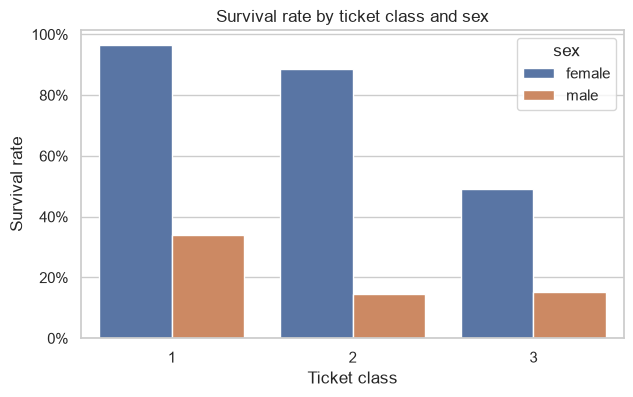

pclass,1,2,3
sex,,,
female,0.97,0.89,0.49
male,0.34,0.15,0.15


In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df, x="pclass", y="survived", hue="sex", errorbar=None, ax=ax)
ax.set(xlabel="Ticket class", ylabel="Survival rate", title="Survival rate by ticket class and sex")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

df.pivot_table(index="sex", columns="pclass", values="survived").round(2)

**Takeaway:** sex is the strongest single signal. Women in first and second class almost all survived, while men in second and third class mostly died. Within each sex, a better class means a better chance.

### Plot 2: age distribution of survivors and non-survivors

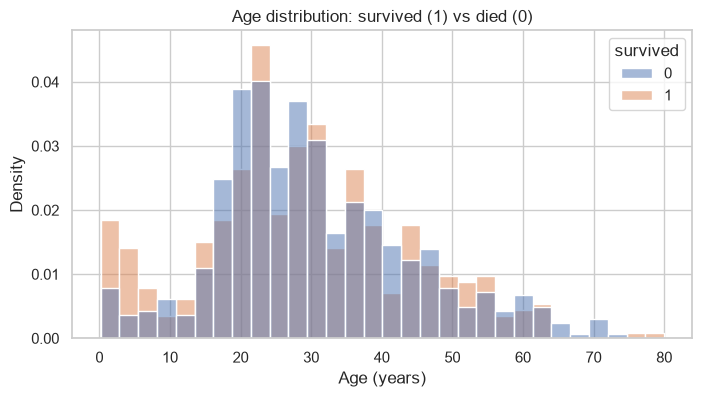

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df.dropna(subset=["age"]), x="age", hue="survived", bins=30,
             multiple="layer", stat="density", common_norm=False, ax=ax)
ax.set(xlabel="Age (years)", title="Age distribution: survived (1) vs died (0)")
plt.show()

**Takeaway:** the two distributions mostly overlap, so age alone is a weak signal. The clear exception is young children (under about 10), who survived more often. That is why the `Master` title is useful.

### Plot 3: survival by family size

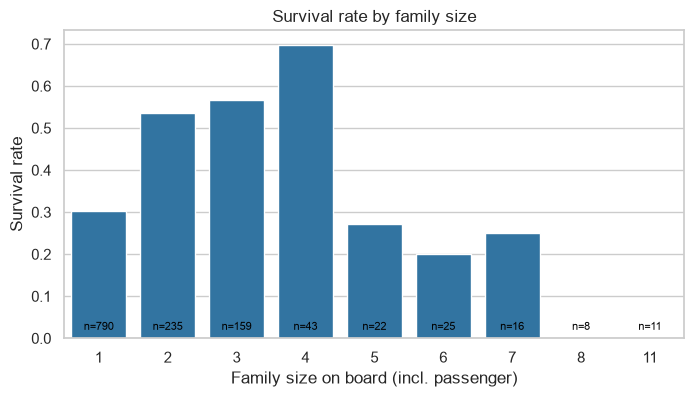

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="family_size", y="survived", errorbar=None, color="tab:blue", ax=ax)
counts = df["family_size"].value_counts().sort_index()
for i, n in enumerate(counts):
    ax.text(i, 0.02, f"n={n}", ha="center", color="black", fontsize=8)
ax.set(xlabel="Family size on board (incl. passenger)", ylabel="Survival rate",
       title="Survival rate by family size")
plt.show()

**Takeaway:** the relationship is **not a straight line**. Travelling alone (1) was worse than travelling in a small family (2 to 4), but large families (5 or more) did worst, probably because it was hard to keep a big group together. A Random Forest can learn a bump like this on its own; a Logistic Regression only sees "more" or "less". Remember this for the model comparison.

## 6. Model

### 6a. Features, target and the train/test split

- **X** (features): the columns the model may use.
- **y** (target): what it must predict, `survived`.

I keep 20% of passengers aside as a **test set**. The models never see them during training, so the test score measures how well a model handles *new* passengers rather than how well it memorised the training ones. `stratify=y` keeps the same 38/62 survival balance in both parts.

In [13]:
numeric = ["age", "fare", "sibsp", "parch", "family_size", "has_cabin", "pclass"]
categorical = ["sex", "embarked", "title"]

X = df[numeric + categorical]
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape)

train: (1047, 10)  test: (262, 10)


### 6b. Preprocessing pipeline

Models need numbers without gaps. A scikit-learn **Pipeline** chains the preparation steps and the model, and learns everything (medians, scaling) from the training data only.

- **Age**: filled with the median age of the passenger's title (computed on training data).
- **Other numbers**: missing values (one `fare`) filled with the median.
- **Text categories** (`sex`, `embarked`, `title`): **one-hot encoded**, meaning each category becomes its own 0/1 column, because a model cannot multiply the word "female". Missing `embarked` gets the most common port.
- **Scaling** (`StandardScaler`, the broadcasting trick from section 1) is only added for Logistic Regression, which is sensitive to the size of numbers (fare goes up to 512, `has_cabin` only to 1). Trees split on thresholds and do not care.

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin


class AgeByTitleImputer(BaseEstimator, TransformerMixin):
    """Fill missing ages with the median age of the passenger's title, learned on the training data."""

    def fit(self, X, y=None):
        self.medians_ = X.groupby("title")["age"].median()
        self.overall_ = X["age"].median()
        return self

    def transform(self, X):
        X = X.copy()
        X["age"] = X["age"].fillna(X["title"].map(self.medians_)).fillna(self.overall_)
        return X


def make_pipeline(model, scale):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    prep = ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])
    return Pipeline([("age", AgeByTitleImputer()), ("prep", prep), ("model", model)])

### 6c. Train three models

1. **Baseline** (`DummyClassifier`): always predicts the most common answer, "died". This is the score to beat.
2. **Logistic Regression**: a linear model. It gives each feature a weight, adds them up, and squashes the sum into a probability between 0 and 1. Simple, fast and easy to explain. This is literally a neural network with a single neuron, the starting point for week 3.
3. **Random Forest**: 300 decision trees, each trained on a random sample of passengers and features, that vote on the answer. Trees can learn non-linear patterns and combinations like "male *and* third class".

Besides the single test score I also run **5-fold cross-validation** on the training set: train on 4/5, validate on the other 1/5, five times over. With only 262 test passengers one lucky or unlucky split can move accuracy by a few percent, so the cross-validation mean and spread show how stable each score is.

In [15]:
models = {
    "Baseline (always 'died')": (DummyClassifier(strategy="most_frequent"), False),
    "Logistic Regression": (LogisticRegression(max_iter=1000), True),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED), False),
}

rows, fitted = [], {}
for name, (model, scale) in models.items():
    pipe = make_pipeline(model, scale)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"model": name,
                 "train accuracy": accuracy_score(y_train, pipe.predict(X_train)),
                 "CV accuracy (mean)": cv.mean(),
                 "CV spread (std)": cv.std(),
                 "test accuracy": accuracy_score(y_test, pipe.predict(X_test))})

results = pd.DataFrame(rows).set_index("model")
results.style.format("{:.1%}")

,train accuracy,CV accuracy (mean),CV spread (std),test accuracy
model,,,,
Baseline (always 'died'),61.8%,61.8%,0.1%,61.8%
Logistic Regression,80.8%,79.9%,1.4%,84.4%
Random Forest,86.3%,80.4%,1.9%,84.7%


### 6d. Where do the models go wrong? Confusion matrices

Accuracy is one number. A **confusion matrix** shows *which* mistakes a model makes: rows are the true answer, columns the prediction. The off-diagonal cells are errors.

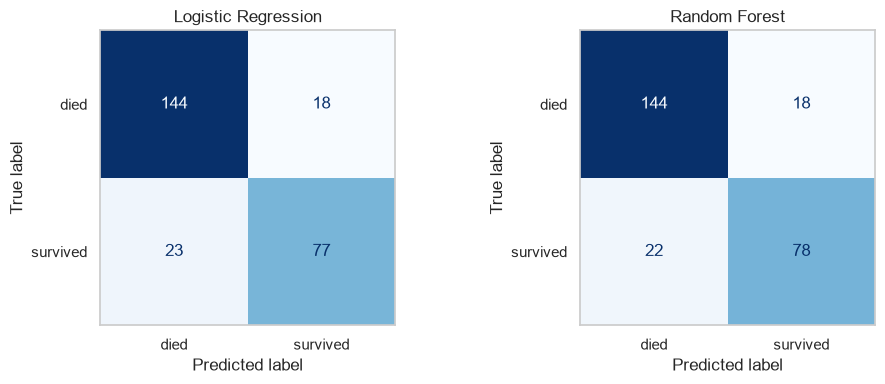

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, display_labels=["died", "survived"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 6e. What did the models learn?

For Logistic Regression the **coefficients** show direction: positive pushes towards *survived*, negative towards *died*. Because the numbers were scaled, sizes are comparable. For the Random Forest, **feature importance** shows how much each feature helped the trees split, but not in which direction.

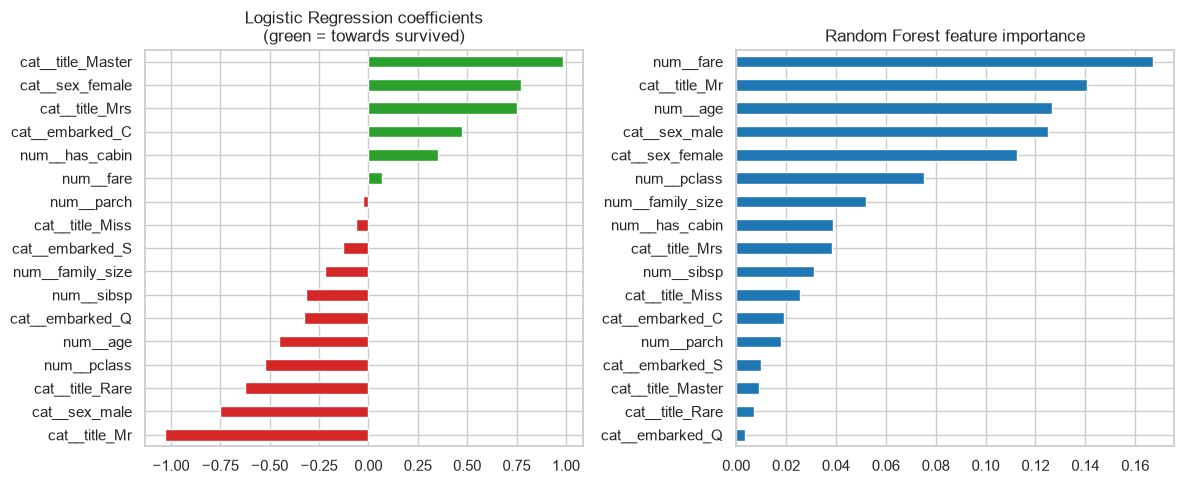

In [17]:
def feature_names(pipe):
    return pipe.named_steps["prep"].get_feature_names_out()

lr = fitted["Logistic Regression"]
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=feature_names(lr)).sort_values()

rf = fitted["Random Forest"]
imps = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names(rf)).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
coefs.plot.barh(ax=axes[0], color=np.where(coefs > 0, "tab:green", "tab:red"))
axes[0].set_title("Logistic Regression coefficients\n(green = towards survived)")
imps.plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

## Results

In [18]:
best = results["test accuracy"].idxmax()
print(f"Best on the test set: {best} with {results.loc[best, 'test accuracy']:.1%} "
      f"(baseline {results.iloc[0]['test accuracy']:.1%})")
results.style.format("{:.1%}")

Best on the test set: Random Forest with 84.7% (baseline 61.8%)


,train accuracy,CV accuracy (mean),CV spread (std),test accuracy
model,,,,
Baseline (always 'died'),61.8%,61.8%,0.1%,61.8%
Logistic Regression,80.8%,79.9%,1.4%,84.4%
Random Forest,86.3%,80.4%,1.9%,84.7%


## Conclusion

**Result:** both models beat the 61.8% baseline by a wide margin. Random Forest scored **84.7%** on the test set and Logistic Regression **84.4%**, a difference of exactly one passenger out of 262.

**Why neither model clearly won (my 3 lines):**

1. *The signal is mostly simple.* Sex, title and ticket class explain most of who survived, and those are "more or less" effects that a linear model like Logistic Regression captures just as well as 300 trees.
2. *The Random Forest's extra power mostly went into memorising.* It scored 86.3% on the training data but 80.4% in cross-validation, a bigger gap than Logistic Regression (80.8% vs 79.9%). Its advantage on non-linear patterns, like the family-size bump in plot 3, was roughly cancelled out by that overfitting.
3. *With only 1,309 passengers, a 0.3% difference is noise.* The cross-validation spread is 1.4 to 1.9%, so on this data I would pick Logistic Regression: it is as accurate, faster and its coefficients explain the decision (title `Master` and sex `female` push towards survival, title `Mr` and lower class push towards death).

**Also worth noting:** both test scores (about 84%) are higher than the cross-validation scores (about 80%), so this particular test split was a bit easy. About 80% is the more honest estimate of how either model would do on new passengers. And dropping the `boat` column mattered: with it, the score would have been above 95%, but only because it tells you who got into a lifeboat.

**Next time I would try:** tuning the Random Forest (fewer, shallower trees to reduce overfitting) and gradient boosting, and checking whether a small neural network (week 3) can beat 80% on this table.